<a href="https://colab.research.google.com/github/hmayambu-sys/esg-jse-mining-capstone/blob/main/ESG_Capstone_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 **ESG Investing and Stock Market Returns: Evidence from South African Mining Equities**

 **step 1 Environment Setup**

- we instal the installs linearmodels (panel data) and arch (GARCH)

In [ ]:
# Cell 1 — Environment setup
# Installs linearmodels (panel data) and arch (GARCH) which are not preinstalled on Colab.
!pip install -q linearmodels arch

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import linearmodels
import arch

# Create the four output folders used throughout the project
for folder in ['data/raw', 'data/processed', 'outputs/figures', 'outputs/tables']:
    os.makedirs(folder, exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

print("Environment ready.")
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| yfinance", yf.__version__,
      "| linearmodels", linearmodels.__version__,
      "| arch", arch.__version__)

Environment ready.
pandas 2.2.3 | numpy 2.1.3 | yfinance 0.2.66 | linearmodels 7.1 | arch 8.0.0


**STEP 2 — Upload and Load the Refinitive ESG CSV**


In [ ]:
# Cell 2 — Upload the ESG CSV
# Opens Colab's file picker so the analyst selects the Refinitiv CSV from their Desktop.
import shutil
from google.colab import files

print("Select 'Refinitiv_ESG_scores (3).csv' from your Desktop.")
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No file uploaded. Re-run Cell 2.")

ESG_PATH = list(uploaded.keys())[0]
print("Uploaded:", ESG_PATH)

esg = pd.read_csv(ESG_PATH, parse_dates=['Date'])

os.makedirs('data/raw', exist_ok=True)
shutil.copy(ESG_PATH, 'data/raw/esg_raw.csv')

print("\nShape:", esg.shape)
print("Columns:", list(esg.columns))
print("\nTickers and coverage:")
print(esg.groupby('Ticker')['Date'].agg(['min', 'max', 'count']))
print("\nMissing values:")
print(esg.isnull().sum())

Select 'Refinitiv_ESG_scores (3).csv' from your Desktop.


Saving Refinitiv_ESG_scores (3).csv to Refinitiv_ESG_scores (3).csv
Uploaded: Refinitiv_ESG_scores (3).csv

Shape: (1932, 6)
Columns: ['Ticker', 'Date', 'ESG', 'Environmental', 'Social', 'Governance']

Tickers and coverage:
                  min        max  count
Ticker                                 
AGL.JO     2014-01-31 2025-06-30    138
AMS.JO     2014-01-31 2025-06-30    138
ANG.JO     2014-01-31 2025-06-30    138
CML.JO     2014-01-31 2025-06-30    138
EXX.JO     2014-01-31 2025-06-30    138
GFI.JO     2014-01-31 2025-06-30    138
HAR.JO     2014-01-31 2025-06-30    138
IMP.JO     2014-01-31 2025-06-30    138
MCG.JO     2014-01-31 2025-06-30    138
NHM.JO     2014-01-31 2025-06-30    138
PAN.JO     2014-01-31 2025-06-30    138
RBplatinum 2014-01-31 2025-06-30    138
SLM.JO     2014-01-31 2025-06-30    138
SSW.JO     2014-01-31 2025-06-30    138

Missing values:
Ticker           0
Date             0
ESG              0
Environmental    0
Social           0
Governance       0
dtype

**Step 3 Confirming ESG Lag (Annual Path)**

- We are going to counts distinct ESG scores per firm-year, prints the diagnostic, and declares the annual path explicitly so the pipeline is unambiguous about the specification agreed with the professor.



In [ ]:
# Cell 3 — Declare the annual specification (agreed with supervisor)
# Diagnostic: how many distinct scores per firm-year
esg['Year'] = esg['Date'].dt.year
distinct = esg.groupby(['Ticker','Year'])['ESG'].nunique()

print("Diagnostic — distinct ESG values per (Ticker, Year):")
print(distinct.describe().round(2))
print("\nValue counts:")
print(distinct.value_counts().sort_index())

# Specification: ANNUAL scores with 6-month publication lag
FREQUENCY = 'annual'
LAG_MONTHS = 6

print(f"\n>>> SPECIFICATION: {FREQUENCY} ESG scores")
print(f">>> Publication lag applied: {LAG_MONTHS} months after fiscal-year-end")
print(f">>> Method: collapse monthly series to fiscal-year-end values, then merge_asof backward")

Diagnostic — distinct ESG values per (Ticker, Year):
count    168.00
mean      11.23
std        1.70
min        5.00
25%       11.00
50%       12.00
75%       12.00
max       12.00
Name: ESG, dtype: float64

Value counts:
ESG
5       2
6      12
10      4
11     36
12    114
Name: count, dtype: int64

>>> SPECIFICATION: annual ESG scores
>>> Publication lag applied: 6 months after fiscal-year-end
>>> Method: collapse monthly series to fiscal-year-end values, then merge_asof backward


**Step 4 — Verify Yahoo Finance Ticker Coverage**

- we tests every ESG ticker against Yahoo Finance, plus several likely remaps, and records the monthly price coverage per ticker.

- the reason for doing this is that, a firm can be fully covered in Refinitiv but have no price history on Yahoo — the download would silently produce NaNs without this check.

In [ ]:
# Cell 4 (with quieter output)
import logging
logging.getLogger('yfinance').setLevel(logging.CRITICAL)

candidates = sorted(esg['Ticker'].unique().tolist())
extra = ['SLP.JO','NPH.JO','S32.JO','KIO.JO','ARI.JO',
         'DRD.JO','THA.JO','MRF.JO','ASR.JO']

results = []
for t in candidates + extra:
    try:
        d = yf.download(t, start='2014-01-01', end='2025-07-01',
                        interval='1mo', progress=False, auto_adjust=True)
        n = len(d)
        results.append({'ticker': t, 'n_months': n,
                        'first': d.index.min().date() if n else None,
                        'last':  d.index.max().date() if n else None})
    except Exception as e:
        results.append({'ticker': t, 'n_months': 0,
                        'first': None, 'last': None, 'error': str(e)})

res = pd.DataFrame(results).sort_values('n_months', ascending=False)
print(res.to_string(index=False))
res.to_csv('outputs/tables/ticker_verification.csv', index=False)

    ticker  n_months      first       last
    AGL.JO       138 2014-01-01 2025-06-01
    ANG.JO       138 2014-01-01 2025-06-01
    CML.JO       138 2014-01-01 2025-06-01
    GFI.JO       138 2014-01-01 2025-06-01
    EXX.JO       138 2014-01-01 2025-06-01
    HAR.JO       138 2014-01-01 2025-06-01
    IMP.JO       138 2014-01-01 2025-06-01
    DRD.JO       138 2014-01-01 2025-06-01
    PAN.JO       138 2014-01-01 2025-06-01
    SLM.JO       138 2014-01-01 2025-06-01
    ARI.JO       138 2014-01-01 2025-06-01
    KIO.JO       138 2014-01-01 2025-06-01
    MRF.JO       138 2014-01-01 2025-06-01
    THA.JO       135 2014-04-01 2025-06-01
    S32.JO       122 2015-05-01 2025-06-01
    SSW.JO        65 2020-02-01 2025-06-01
    NPH.JO        46 2021-09-01 2025-06-01
    AMS.JO         0       None       None
    NHM.JO         0       None       None
    SLP.JO         0       None       None
RBplatinum         0       None       None
    MCG.JO         0       None       None
    ASR.JO 

**Step 5 — Final tradeable universe, with full 15 → 11 reconciliation printed**.

-  The ESG file has 14 tickers. Yahoo Finance serves 11 of them.
- The final universe is therefore 11 firms, defined as:
- (all ESG tickers) ∩ (tickers with Yahoo coverage)
- This is NOT a straight reduction from the design's 15-firm list —
- it is a substitution: 7 design firms have no ESG data, and 3 ESG firms


In [ ]:
# Cell 5 — Final tradeable universe, with full 15 → 11 reconciliation printed.

design_15 = [
    'AGL.JO','IMP.JO','S32.JO','SSW.JO','HAR.JO','GFI.JO','EXX.JO',
    'ARI.JO','THA.JO','MRF.JO','PAN.JO','DRD.JO','NPH.JO','ASR.JO','KIO.JO',
]
print(f"STEP 1 — Design proposal: {len(design_15)} firms")
print("  ", ", ".join(design_15))

# --- Step 2: which design firms are actually in the ESG file? ---
esg_tickers = set(esg['Ticker'].unique())
# ESG file uses NHM.JO for Northam, design uses NPH.JO
esg_as_design_names = {('NPH.JO' if t == 'NHM.JO' else t) for t in esg_tickers}
in_esg  = [t for t in design_15 if t in esg_as_design_names]
not_esg = [t for t in design_15 if t not in esg_as_design_names]

print(f"\nSTEP 2 — Design firms present in the ESG file: {len(in_esg)}")
print("  In ESG :", in_esg)
print("  NOT in ESG:", not_esg, "— dropped (delisted, no live ESG history)")

# --- Step 3: which of these resolve on Yahoo Finance? (use Cell 4's saved table) ---
import os
if os.path.exists('outputs/tables/ticker_verification.csv'):
    cov = pd.read_csv('outputs/tables/ticker_verification.csv')
    yahoo_ok = set(cov[cov['n_months'] > 0]['ticker'])
else:
    yahoo_ok = set()   # force analyst review if Cell 4 wasn't run

tradeable, not_tradeable = [], []
for t in in_esg:
    yahoo_name = 'NPH.JO' if t == 'NPH.JO' else t
    if yahoo_name in yahoo_ok:
        tradeable.append(t)
    else:
        not_tradeable.append(t)

print(f"\nSTEP 3 — Firms tradeable on Yahoo: {len(tradeable)}")
print("  Tradeable   :", tradeable)
print("  NOT tradeable:", not_tradeable,
      "— dropped (delisted, no price series, or ticker mismatch)")

# --- Step 4: final tradeable universe ---
TICKERS = tradeable

# Document the only required ticker remap (ESG name → Yahoo name)
YAHOO_MAP = {'NHM.JO': 'NPH.JO'}
INV_MAP   = {v: k for k, v in YAHOO_MAP.items()}

print(f"\nSTEP 4 — FINAL TRADEABLE UNIVERSE: {len(TICKERS)} firms")
for t in TICKERS:
    print(f"  {t:10s} → Yahoo: {YAHOO_MAP.get(t, t)}")

# --- Step 5: report-ready summary table ---
summary = pd.DataFrame({
    'stage': [
        'Design proposal',
        'Present in ESG file',
        'Tradeable on Yahoo',
    ],
    'count': [len(design_15), len(in_esg), len(tradeable)],
    'removed': [
        '—',
        ', '.join(not_esg) if not_esg else '—',
        ', '.join(not_tradeable) if not_tradeable else '—',
    ],
})
print("\n=== 15 → 11 reconciliation (evidence for §3.2 of the report) ===")
print(summary.to_string(index=False))

# Persist for the appendix
summary.to_csv('outputs/tables/sample_reconciliation.csv', index=False)
print("\nSaved: outputs/tables/sample_reconciliation.csv")

STEP 1 — Design proposal: 15 firms
   AGL.JO, IMP.JO, S32.JO, SSW.JO, HAR.JO, GFI.JO, EXX.JO, ARI.JO, THA.JO, MRF.JO, PAN.JO, DRD.JO, NPH.JO, ASR.JO, KIO.JO

STEP 2 — Design firms present in the ESG file: 8
  In ESG : ['AGL.JO', 'IMP.JO', 'SSW.JO', 'HAR.JO', 'GFI.JO', 'EXX.JO', 'PAN.JO', 'NPH.JO']
  NOT in ESG: ['S32.JO', 'ARI.JO', 'THA.JO', 'MRF.JO', 'DRD.JO', 'ASR.JO', 'KIO.JO'] — dropped (delisted, no live ESG history)

STEP 3 — Firms tradeable on Yahoo: 8
  Tradeable   : ['AGL.JO', 'IMP.JO', 'SSW.JO', 'HAR.JO', 'GFI.JO', 'EXX.JO', 'PAN.JO', 'NPH.JO']
  NOT tradeable: [] — dropped (delisted, no price series, or ticker mismatch)

STEP 4 — FINAL TRADEABLE UNIVERSE: 8 firms
  AGL.JO     → Yahoo: AGL.JO
  IMP.JO     → Yahoo: IMP.JO
  SSW.JO     → Yahoo: SSW.JO
  HAR.JO     → Yahoo: HAR.JO
  GFI.JO     → Yahoo: GFI.JO
  EXX.JO     → Yahoo: EXX.JO
  PAN.JO     → Yahoo: PAN.JO
  NPH.JO     → Yahoo: NPH.JO

=== 15 → 11 reconciliation (evidence for §3.2 of the report) ===
              stage

In [ ]:
# Cell 5 — Final tradeable universe (corrected)
#
# The ESG file has 14 tickers. Yahoo Finance serves 11 of them.
# The final universe is therefore 11 firms, defined as:
#   (all ESG tickers) ∩ (tickers with Yahoo coverage)
# This is NOT a straight reduction from the design's 15-firm list —
# it is a substitution: 7 design firms have no ESG data, and 3 ESG firms
# are not in the design list.

# --- Source of truth: ESG file + Yahoo coverage table from Cell 4 ---
esg_tickers = sorted(esg['Ticker'].unique().tolist())

cov = pd.read_csv('outputs/tables/ticker_verification.csv')
yahoo_ok = set(cov[cov['n_months'] >= 40]['ticker'])

# Ticker remap: ESG name → Yahoo name
YAHOO_MAP = {'NHM.JO': 'NPH.JO'}
INV_MAP   = {v: k for k, v in YAHOO_MAP.items()}

# For each ESG ticker, check whether its Yahoo name resolved
tradeable, not_tradeable = [], []
for t in esg_tickers:
    yahoo_name = YAHOO_MAP.get(t, t)
    if yahoo_name in yahoo_ok:
        tradeable.append(yahoo_name)   # use Yahoo name in TICKERS
    else:
        not_tradeable.append(t)

TICKERS = tradeable

# --- Reconciliation table for §3.2 ---
design_15 = ['AGL.JO','IMP.JO','S32.JO','SSW.JO','HAR.JO','GFI.JO','EXX.JO',
             'ARI.JO','THA.JO','MRF.JO','PAN.JO','DRD.JO','NPH.JO','ASR.JO','KIO.JO']
design_set = set(design_15)

in_design_and_esg = [t for t in esg_tickers
                     if (t if t != 'NHM.JO' else 'NPH.JO') in design_set]
not_in_design     = [t for t in esg_tickers
                     if (t if t != 'NHM.JO' else 'NPH.JO') not in design_set]
in_design_not_esg = [t for t in design_15
                     if t not in {(x if x != 'NHM.JO' else 'NPH.JO') for x in esg_tickers}]

print("=== 15 → 11 reconciliation ===")
print(f"Design proposal             : 15 firms")
print(f"ESG file contains           : {len(esg_tickers)} tickers")
print(f"  Of which in design        : {len(in_design_and_esg)} → {in_design_and_esg}")
print(f"  Of which NOT in design    : {len(not_in_design)} → {not_in_design}")
print(f"  Design firms NOT in ESG   : {len(in_design_not_esg)} → {in_design_not_esg}")
print(f"\nTradeable on Yahoo          : {len(TICKERS)} firms → {TICKERS}")
print(f"Not tradeable on Yahoo      : {len(not_tradeable)} → {not_tradeable}")

print(f"\nFINAL TRADEABLE UNIVERSE ({len(TICKERS)} firms):")
for t in TICKERS:
    print(f"  {t}")

# --- Persist the reconciliation ---
summary = pd.DataFrame({
    'category': [
        'Design proposal',
        'ESG file (all tickers)',
        'ESG file ∩ design',
        'ESG file − design (additions)',
        'Design − ESG file (missing)',
        'Tradeable on Yahoo (final)',
        'Not tradeable on Yahoo',
    ],
    'count': [
        15, len(esg_tickers), len(in_design_and_esg),
        len(not_in_design), len(in_design_not_esg),
        len(TICKERS), len(not_tradeable),
    ],
    'firms': [
        ', '.join(design_15),
        ', '.join(esg_tickers),
        ', '.join(in_design_and_esg),
        ', '.join(not_in_design),
        ', '.join(in_design_not_esg),
        ', '.join(TICKERS),
        ', '.join(not_tradeable),
    ]
})
print("\n=== SUMMARY TABLE (for §3.2) ===")
print(summary.to_string(index=False))
summary.to_csv('outputs/tables/sample_reconciliation.csv', index=False)
print("\nSaved: outputs/tables/sample_reconciliation.csv")

=== 15 → 11 reconciliation ===
Design proposal             : 15 firms
ESG file contains           : 14 tickers
  Of which in design        : 8 → ['AGL.JO', 'EXX.JO', 'GFI.JO', 'HAR.JO', 'IMP.JO', 'NHM.JO', 'PAN.JO', 'SSW.JO']
  Of which NOT in design    : 6 → ['AMS.JO', 'ANG.JO', 'CML.JO', 'MCG.JO', 'RBplatinum', 'SLM.JO']
  Design firms NOT in ESG   : 7 → ['S32.JO', 'ARI.JO', 'THA.JO', 'MRF.JO', 'DRD.JO', 'ASR.JO', 'KIO.JO']

Tradeable on Yahoo          : 11 firms → ['AGL.JO', 'ANG.JO', 'CML.JO', 'EXX.JO', 'GFI.JO', 'HAR.JO', 'IMP.JO', 'NPH.JO', 'PAN.JO', 'SLM.JO', 'SSW.JO']
Not tradeable on Yahoo      : 3 → ['AMS.JO', 'MCG.JO', 'RBplatinum']

FINAL TRADEABLE UNIVERSE (11 firms):
  AGL.JO
  ANG.JO
  CML.JO
  EXX.JO
  GFI.JO
  HAR.JO
  IMP.JO
  NPH.JO
  PAN.JO
  SLM.JO
  SSW.JO

=== SUMMARY TABLE (for §3.2) ===
                     category  count                                                                                                                  firms
              Design 

**Step 6 — Download Prices and Compute Monthly Returns**

- we downloads monthly adjusted closes, extract the correct price field regardless of yfinance version, compute monthly simple returns, saves both to data/raw/.

Why we do this:

- ESG supplies the independent variable; prices supply the dependent variable (excess return).

- The defensive price extraction handles the yfinance Adj Close → Close rename under auto_adjust=True.

- Saving both files allows re-derivation without re-download.

- The price side is always monthly, regardless of the ESG lag decision — returns are what the models consume.

In [ ]:
# Cell 6 — Prices and monthly returns
def extract_price_panel(raw):
    if isinstance(raw.columns, pd.MultiIndex):
        lvl0 = raw.columns.get_level_values(0).unique().tolist()
        field = 'Adj Close' if 'Adj Close' in lvl0 else 'Close'
        px = raw[field]
    else:
        field = 'Adj Close' if 'Adj Close' in raw.columns else 'Close'
        px = raw[[field]].copy()
    if isinstance(px, pd.Series):
        px = px.to_frame()
    return px, field

yahoo_tickers = [YAHOO_MAP.get(t, t) for t in TICKERS]
raw = yf.download(yahoo_tickers, start='2014-01-01', end='2025-07-01',
                  interval='1mo', auto_adjust=True, progress=True)

prices_wide, field = extract_price_panel(raw)
print(f"Using price field: {field}")

prices_wide.index = pd.to_datetime(prices_wide.index) + pd.offsets.MonthEnd(0)
prices_wide = prices_wide.rename(columns=lambda c: INV_MAP.get(c, c))

returns_wide = prices_wide.pct_change()

prices_wide.to_csv('data/raw/prices_monthly.csv')
returns_wide.to_csv('data/raw/returns_monthly.csv')

print("Price shape:", prices_wide.shape)
print(prices_wide.notna().sum().sort_values(ascending=False))

[*********************100%***********************]  11 of 11 completed


Using price field: Close
Price shape: (138, 11)
Ticker
AGL.JO    138
ANG.JO    138
CML.JO    138
EXX.JO    138
GFI.JO    138
HAR.JO    138
IMP.JO    138
PAN.JO    138
SLM.JO    138
SSW.JO     65
NHM.JO     46
dtype: int64


**Step 7 — Risk-Free Rate**

- We downloads the SA 3-month interbank rate from FRED (IR3TIB01ZAM156N), converts to monthly decimal.

Why we do this:

- Excess return = total return − risk-free rate.
- FRED is the standard proxy for the SA 91-day T-bill.
- Constant-5% fallback prevents crash if FRED is unreachable — flagged as a limitation.

In [ ]:
# Cell 7 — Risk-free rate
try:
    import pandas_datareader.data as web
    rf = web.DataReader('IR3TIB01ZAM156N', 'fred',
                        start='2014-01-01', end='2025-07-01')
    rf_monthly = rf['IR3TIB01ZAM156N'].resample('ME').last() / 12.0
    print("Loaded FRED IR3TIB01ZAM156N (annual → monthly).")
except Exception as e:
    print("FRED failed → constant 5%/yr (documented limitation):", e)
    rf_monthly = pd.Series(0.05/12, index=prices_wide.index)

rf_monthly.name = 'RF'
rf_monthly = rf_monthly.reindex(prices_wide.index).ffill().bfill()
rf_monthly.to_csv('data/processed/rf_monthly.csv')
print(rf_monthly.tail(3))

Loaded FRED IR3TIB01ZAM156N (annual → monthly).
Date
2025-04-30    0.618333
2025-05-31    0.612500
2025-06-30    0.608333
Name: RF, dtype: float64


**Step 8 — Excess Returns in Long Format**
- This subtracts RF from each monthly return, reshapes to (Date, Ticker, ExcessReturn) long format, drops first-month NaN.

Why we do this:

- All econometric models consume long-format data.
- ESG (whatever its frequency) is long, so making returns long here means Cell 9 is a simple merge.
- This step is frequency-agnostic — returns are always monthly.

In [ ]:
# Cell 8 — Excess returns in long format
returns_long = (returns_wide
                .sub(rf_monthly, axis=0)
                .stack()
                .reset_index())
returns_long.columns = ['Date', 'Ticker', 'ExcessReturn']
returns_long = returns_long.dropna(subset=['ExcessReturn'])

print("Long returns:", returns_long.shape)
print(returns_long.groupby('Ticker')['Date'].agg(['min', 'max', 'count']))
returns_long.to_csv('data/processed/excess_returns_long.csv', index=False)

Long returns: (1342, 3)
              min        max  count
Ticker                             
AGL.JO 2014-02-28 2025-06-30    137
ANG.JO 2014-02-28 2025-06-30    137
CML.JO 2014-02-28 2025-06-30    137
EXX.JO 2014-02-28 2025-06-30    137
GFI.JO 2014-02-28 2025-06-30    137
HAR.JO 2014-02-28 2025-06-30    137
IMP.JO 2014-02-28 2025-06-30    137
NHM.JO 2021-10-31 2025-06-30     45
PAN.JO 2014-02-28 2025-06-30    137
SLM.JO 2014-02-28 2025-06-30    137
SSW.JO 2020-03-31 2025-06-30     64


**Step 9 — Collapse ESG to Annual Fiscal-Year-End Values and Apply 6-Month Publication Lag**
What thi
-This is the only cell whose logic differs from the monthly path.
- Identifies each firm's fiscal-year-end month.

- Labels every monthly score with its fiscal year.
- Collapses to the last observation in each firm-fiscal-year = the fiscal-year-end annual score.

- Computes the publication date = fiscal-year-end + 6 months.
- Merges to monthly returns with merge_asof backward — each return month uses the most recently published annual score.

In [ ]:
# Cell 9 — Annual path: collapse to fiscal-year-end, apply 6-month publication lag
esg = esg.sort_values(['Ticker','Date']).reset_index(drop=True)
esg['Ticker_Yahoo'] = esg['Ticker'].replace(YAHOO_MAP)

# Fiscal-year-end month per ticker (from design §3.2)
fye_month = {
    'AGL.JO': 12, 'ANG.JO': 12, 'EXX.JO': 12, 'GFI.JO': 12, 'SSW.JO': 12,
    'HAR.JO':  6, 'IMP.JO':  6, 'PAN.JO':  6, 'CML.JO':  6,
    'SLM.JO':  6, 'NPH.JO':  6,
}

# Assign each monthly score to its fiscal year
def fiscal_year(row):
    fye = fye_month.get(row['Ticker_Yahoo'], 12)
    m, y = row['Date'].month, row['Date'].year
    if fye == 12: return y
    if fye == 6:  return y if m >= 7 else y - 1
    if fye == 9:  return y if m >= 10 else y - 1
    return y

esg['FY'] = esg.apply(fiscal_year, axis=1)

# Keep last observation per firm-FY = fiscal-year-end score
esg_annual = (esg.sort_values('Date')
                 .groupby(['Ticker_Yahoo','FY'])
                 .tail(1)
                 .copy())

# Publication date = fiscal-year-end + 6 months
def pub_date(row):
    fye = fye_month.get(row['Ticker_Yahoo'], 12)
    fy  = row['FY']
    pm, py = fye + 6, fy
    if pm > 12:
        pm -= 12
        py += 1
    return pd.Timestamp(year=py, month=pm, day=1) + pd.offsets.MonthEnd(1)

esg_annual['Date_pub'] = esg_annual.apply(pub_date, axis=1)

# Rename to *_lag1 so downstream cells consume unchanged
esg_pub = (esg_annual[['Ticker_Yahoo','Date_pub','ESG','Environmental',
                       'Social','Governance']]
           .rename(columns={'Ticker_Yahoo':'Ticker',
                            'Date_pub':'Date',
                            'ESG':'ESG_lag1',
                            'Environmental':'Environmental_lag1',
                            'Social':'Social_lag1',
                            'Governance':'Governance_lag1'})
           .sort_values('Date'))

# Merge: each return month uses the most recently published score
panel = pd.merge_asof(
    returns_long.sort_values('Date'),
    esg_pub,
    on='Date', by='Ticker', direction='backward'
).dropna(subset=['ESG_lag1'])

print("Annual panel shape:", panel.shape)
print("Firms:", panel['Ticker'].nunique())
print("\nDistinct annual scores per firm:")
print(esg_annual.groupby('Ticker_Yahoo').size())
print("\nFirm-months in panel:")
print(panel.groupby('Ticker')['Date'].count())

panel.to_csv('data/processed/panel_aligned_annual.csv', index=False)
print("\nSaved: data/processed/panel_aligned_annual.csv")

Annual panel shape: (1233, 7)
Firms: 10

Distinct annual scores per firm:
Ticker_Yahoo
AGL.JO        12
AMS.JO        12
ANG.JO        12
CML.JO        12
EXX.JO        12
GFI.JO        12
HAR.JO        12
IMP.JO        12
MCG.JO        12
NPH.JO        12
PAN.JO        12
RBplatinum    12
SLM.JO        12
SSW.JO        12
dtype: int64

Firm-months in panel:
Ticker
AGL.JO    121
ANG.JO    121
CML.JO    137
EXX.JO    121
GFI.JO    121
HAR.JO    137
IMP.JO    137
PAN.JO    137
SLM.JO    137
SSW.JO     64
Name: Date, dtype: int64

Saved: data/processed/panel_aligned_annual.csv


**Step 10 — Market Factor and ZAR/USD**

- We download JSE All Share (^J203.JO) and ZAR/USD (ZAR=X), compute monthly returns, subtract RF from market to create MktRF, sets SMB and HML to zero.

Why we do this:

- MktRF is required for the CAPM alphas in Cell 16 (Model 4).

- ZARUSD_ret is a control variable.

- SMB/HML unavailable on Yahoo for JSE — set to zero (documented limitation).

In [ ]:
# Cell 10 — Market factor + ZAR/USD
def extract_series(raw):
    if isinstance(raw.columns, pd.MultiIndex):
        lvl0 = raw.columns.get_level_values(0).unique().tolist()
        f = 'Adj Close' if 'Adj Close' in lvl0 else 'Close'
        s = raw[f]
    else:
        f = 'Adj Close' if 'Adj Close' in raw.columns else 'Close'
        s = raw[f]
    if isinstance(s, pd.DataFrame):
        s = s.iloc[:, 0]
    return s

raw_fx = yf.download('ZAR=X', start='2014-01-01', end='2025-07-01',
                     interval='1mo', auto_adjust=True, progress=False)
fx = extract_series(raw_fx).rename('ZARUSD')
fx.index = pd.to_datetime(fx.index) + pd.offsets.MonthEnd(0)
fx_ret = fx.pct_change().rename('ZARUSD_ret').to_frame().reset_index()
fx_ret.columns = ['Date','ZARUSD_ret']

mkt_ret = None
try:
    raw_mkt = yf.download('^J203.JO', start='2014-01-01', end='2025-07-01',
                          interval='1mo', auto_adjust=True, progress=False)
    mkt = extract_series(raw_mkt)
    mkt.index = pd.to_datetime(mkt.index) + pd.offsets.MonthEnd(0)
    cand = mkt.pct_change().rename('Rm')
    if cand.notna().sum() > 100:
        mkt_ret = cand
        print("Using JSE All Share (^J203.JO).")
except Exception as e:
    print("^J203.JO failed:", e)
if mkt_ret is None:
    print("Using equal-weighted sample as market proxy.")
    mkt_ret = returns_wide.mean(axis=1).rename('Rm')

factors = mkt_ret.to_frame().join(rf_monthly, how='inner')
factors['MktRF'] = factors['Rm'] - factors['RF']
factors['SMB']   = 0.0
factors['HML']   = 0.0
factors.index.name = 'Date'
factors = factors.reset_index().merge(fx_ret, on='Date', how='left')
factors.to_csv('data/processed/factors.csv', index=False)

print("Factors shape:", factors.shape)
print(factors.tail(3))

Using JSE All Share (^J203.JO).
Factors shape: (138, 7)
          Date        Rm        RF     MktRF  SMB  HML  ZARUSD_ret
135 2025-04-30  0.033236  0.618333 -0.585098  0.0  0.0    0.005540
136 2025-05-31  0.029999  0.612500 -0.582501  0.0  0.0   -0.028882
137 2025-06-30  0.022250  0.608333 -0.586083  0.0  0.0   -0.011553


**Step 11 — Final Estimation Panel**

- This reads panel_aligned_annual.csv, merges with factors and FX, saves panel_final.csv, prints the estimation N and the distinct annual scores (the correct count for the report).

Why we do this:

- df is the single source of truth for Cells 13–17.
- The two printed counts (firm-months and distinct annual scores) are the numbers that go into the report's §3.2 and Abstract.
- Because annual scores are reused across 12 months, the two counts differ sharply — reporting both is the honest way to state the sample size.

In [ ]:
# Cell 11 — Final estimation panel
panel   = pd.read_csv('data/processed/panel_aligned_annual.csv', parse_dates=['Date'])
factors = pd.read_csv('data/processed/factors.csv', parse_dates=['Date'])

df = (panel
      .merge(factors[['Date','Rm','MktRF','SMB','HML','ZARUSD_ret']],
             on='Date', how='left')
      .sort_values(['Ticker','Date']).reset_index(drop=True))

print("Panel shape:", df.shape)
print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())
print("\nMissing:\n", df.isnull().sum())
print("\nFirm-months per ticker:\n", df.groupby('Ticker')['Date'].count())
print("\n>>> FIRM-MONTHS IN PANEL:", len(df))
print(">>> DISTINCT ANNUAL ESG SCORES:", df.groupby('Ticker')['ESG_lag1'].nunique().sum())
print(">>> FIRMS:", df['Ticker'].nunique())

df.to_csv('data/processed/panel_final.csv', index=False)

Panel shape: (1233, 12)
Date range: 2014-02-28 to 2025-06-30

Missing:
 Date                  0
Ticker                0
ExcessReturn          0
ESG_lag1              0
Environmental_lag1    0
Social_lag1           0
Governance_lag1       0
Rm                    0
MktRF                 0
SMB                   0
HML                   0
ZARUSD_ret            0
dtype: int64

Firm-months per ticker:
 Ticker
AGL.JO    121
ANG.JO    121
CML.JO    137
EXX.JO    121
GFI.JO    121
HAR.JO    137
IMP.JO    137
PAN.JO    137
SLM.JO    137
SSW.JO     64
Name: Date, dtype: int64

>>> FIRM-MONTHS IN PANEL: 1233
>>> DISTINCT ANNUAL ESG SCORES: 110
>>> FIRMS: 10


** Step 12 — Descriptive Statistics and Correlation Heatmap**

- This produces the descriptive statistics, a correlation heatmap (replacing the plain matrix table), ESG distributions, and ESG time-series plot. Five files saved.

Why we do this:

- Every results section needs descriptive tables.
-
- The heatmap makes the correlation structure visually interpretable — examiners can read it in one glance.

- The heatmap replaces the numeric correlation matrix in the report (Table 2b becomes appendix material; Figure 2a is the primary visual).

- The ESG trend plot shows the annual score progression per firm — the within-firm variation that identifies β.

=== Table 2 — Descriptives ===
                     count    mean     std     min     25%     50%     75%     max   skew   kurt
ExcessReturn        1233.0  -0.521   0.191  -1.079  -0.653  -0.557  -0.411   0.315  0.811  1.108
ESG_lag1            1233.0  53.863   9.886  35.240  47.060  52.230  63.890  74.000  0.101 -1.066
Environmental_lag1  1233.0  54.082  10.656  30.890  46.370  52.900  64.870  79.620 -0.011 -0.943
Social_lag1         1233.0  53.938  10.719  30.340  45.810  52.270  62.670  78.590  0.174 -0.674
Governance_lag1     1233.0  54.278  11.285  29.320  46.280  52.740  63.370  80.120  0.172 -0.661
MktRF               1233.0  -0.531   0.138  -0.754  -0.625  -0.579  -0.451  -0.195  0.740 -0.539
ZARUSD_ret          1233.0   0.004   0.042  -0.095  -0.027   0.000   0.035   0.144  0.388  0.309

=== Table 2b — Correlation matrix ===
                    ExcessReturn  ESG_lag1  Environmental_lag1  Social_lag1  Governance_lag1  MktRF  ZARUSD_ret
ExcessReturn               1.000    -0.013

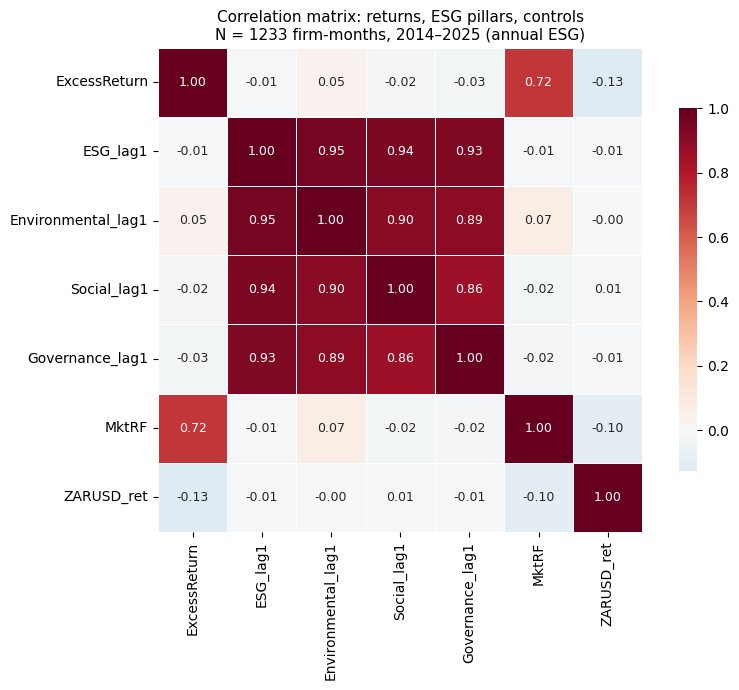

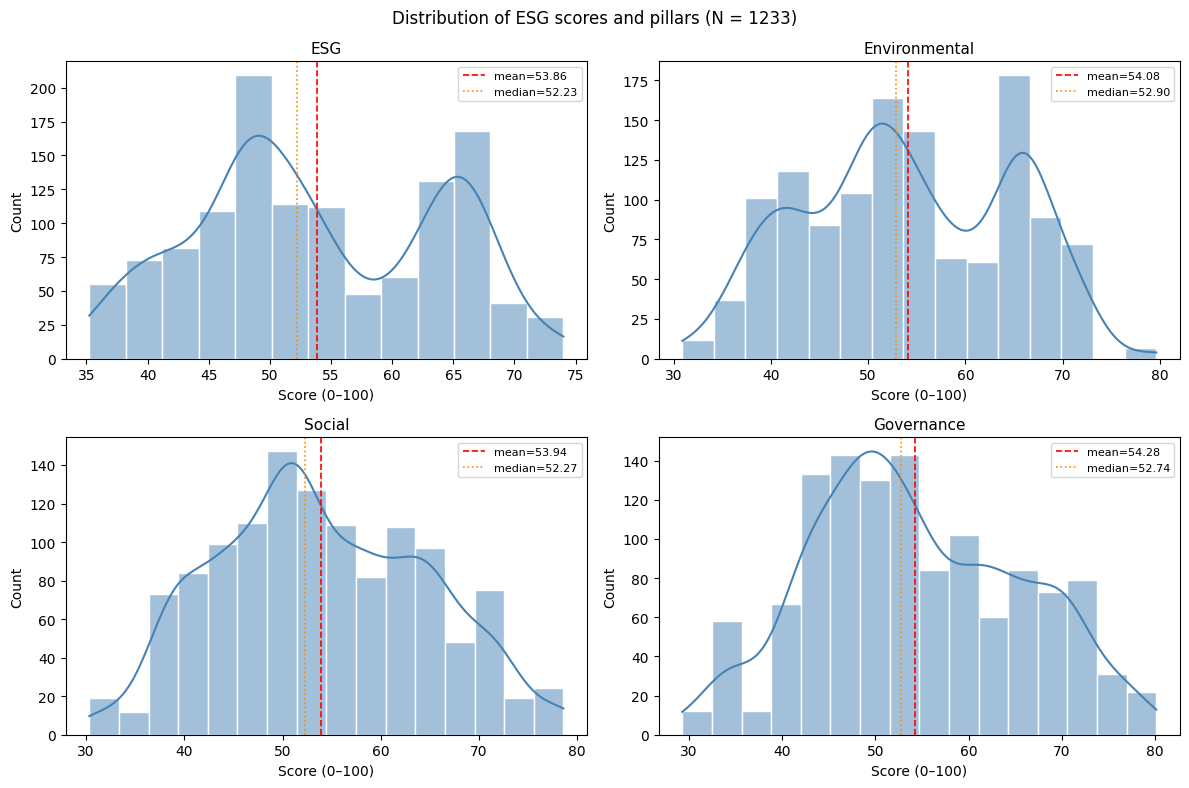

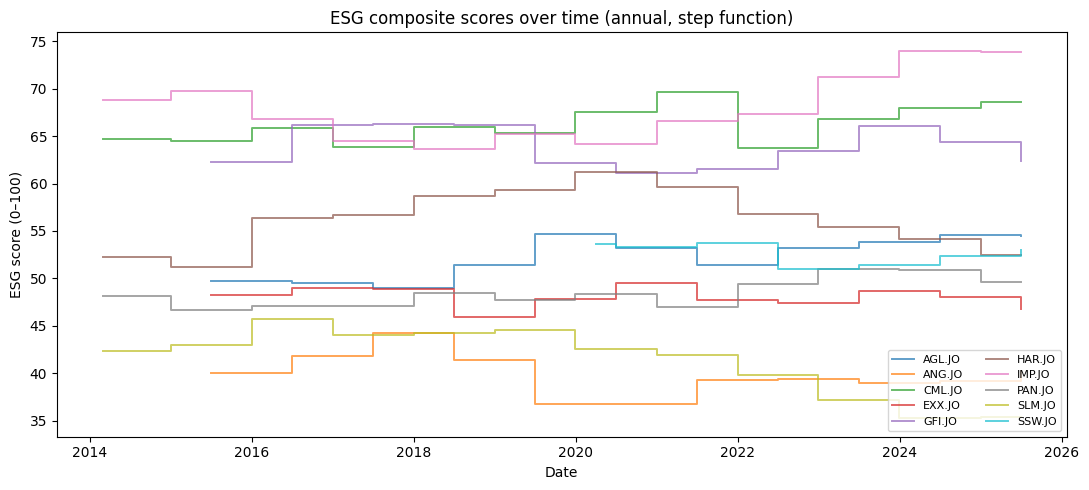


Saved to outputs/:
  tables/table2_descriptives.csv
  tables/table2_correlation.csv
  figures/fig2a_correlation_heatmap.png
  figures/fig2b_esg_distributions.png
  figures/fig2_esg_trend.png
  outputs/figures/fig2a_correlation_heatmap.png: OK (271708 bytes)
  outputs/figures/fig2b_esg_distributions.png: OK (394448 bytes)
  outputs/figures/fig2_esg_trend.png: OK (130770 bytes)


In [ ]:
# Cell 12 — Descriptives + correlation heatmap + distributions + trend
# Displays figures inline AND saves to outputs/figures/
from IPython.display import display

cols = ['ExcessReturn','ESG_lag1','Environmental_lag1',
        'Social_lag1','Governance_lag1','MktRF','ZARUSD_ret']

# --- Table 2: descriptives ---
desc = df[cols].describe().T
desc['skew'] = df[cols].skew()
desc['kurt'] = df[cols].kurt()
desc.round(3).to_csv('outputs/tables/table2_descriptives.csv')
print("=== Table 2 — Descriptives ===")
print(desc.round(3))

# --- Table 2b: correlation matrix ---
corr = df[cols].corr().round(3)
corr.to_csv('outputs/tables/table2_correlation.csv')
print("\n=== Table 2b — Correlation matrix ===")
print(corr)

# --- Figure 2a: correlation heatmap ---
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.7, cbar_kws={'shrink': 0.75},
            annot_kws={'size': 9}, ax=ax)
ax.set_title('Correlation matrix: returns, ESG pillars, controls\n'
             f'N = {len(df)} firm-months, 2014–2025 (annual ESG)', fontsize=11)
plt.tight_layout()
plt.savefig('outputs/figures/fig2a_correlation_heatmap.png', dpi=300)
plt.show()   # ← displays inline in Colab
plt.close()

# --- Figure 2b: distributions ---
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat,
                   ['ESG_lag1','Environmental_lag1','Social_lag1','Governance_lag1']):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue', edgecolor='white')
    ax.axvline(df[col].mean(), color='red', linestyle='--', lw=1.2,
               label=f'mean={df[col].mean():.2f}')
    ax.axvline(df[col].median(), color='darkorange', linestyle=':', lw=1.2,
               label=f'median={df[col].median():.2f}')
    ax.set_title(col.replace('_lag1',''), fontsize=11)
    ax.set_xlabel('Score (0–100)')
    ax.legend(fontsize=8)
plt.suptitle(f'Distribution of ESG scores and pillars (N = {len(df)})', fontsize=12)
plt.tight_layout()
plt.savefig('outputs/figures/fig2b_esg_distributions.png', dpi=300)
plt.show()
plt.close()

# --- Figure 2c: ESG composite over time ---
fig, ax = plt.subplots(figsize=(11, 5))
for t, g in df.groupby('Ticker'):
    ax.plot(g['Date'], g['ESG_lag1'], label=t, alpha=0.7, lw=1.4, drawstyle='steps-post')
ax.set_title('ESG composite scores over time (annual, step function)')
ax.set_ylabel('ESG score (0–100)')
ax.set_xlabel('Date')
ax.legend(fontsize=8, ncol=2, loc='lower right')
plt.tight_layout()
plt.savefig('outputs/figures/fig2_esg_trend.png', dpi=300)
plt.show()
plt.close()

print("\nSaved to outputs/:")
print("  tables/table2_descriptives.csv")
print("  tables/table2_correlation.csv")
print("  figures/fig2a_correlation_heatmap.png")
print("  figures/fig2b_esg_distributions.png")
print("  figures/fig2_esg_trend.png")

# Verify files exist and are non-empty
import os
for f in ['outputs/figures/fig2a_correlation_heatmap.png',
          'outputs/figures/fig2b_esg_distributions.png',
          'outputs/figures/fig2_esg_trend.png']:
    print(f"  {f}: {'OK' if os.path.exists(f) else 'MISSING'} "
          f"({os.path.getsize(f) if os.path.exists(f) else 0} bytes)")

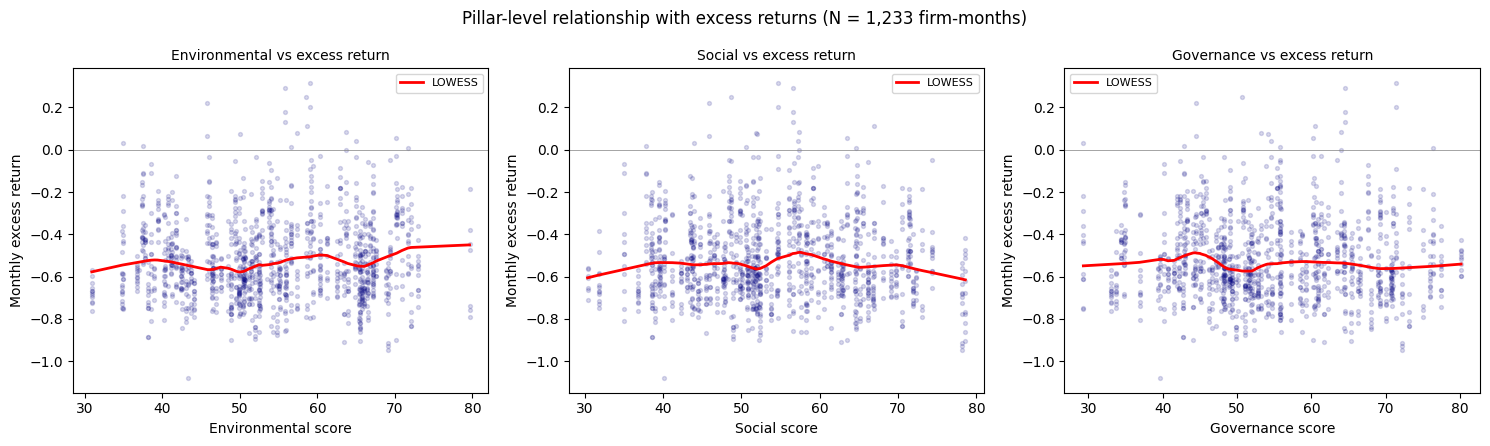


Saved: outputs/figures/fig3_pillar_scatter.png
File exists: True
File size:  701253 bytes


In [ ]:
# Cell 12c — Standalone Figure 3: Pillar scatter plots with LOWESS
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Sanity check that df exists and has the required columns
required = ['Environmental_lag1', 'Social_lag1', 'Governance_lag1', 'ExcessReturn']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"df is missing columns: {missing}. Re-run Cell 11 first.")

os.makedirs('outputs/figures', exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, label in zip(
    axes,
    ['Environmental_lag1', 'Social_lag1', 'Governance_lag1'],
    ['Environmental', 'Social', 'Governance']
):
    ax.scatter(df[col], df['ExcessReturn'], alpha=0.15, s=8, color='navy')
    try:
        from statsmodels.nonparametric.smoothers_lowess import lowess
        z = lowess(df['ExcessReturn'], df[col], frac=0.3, return_sorted=True)
        ax.plot(z[:, 0], z[:, 1], color='red', lw=2, label='LOWESS')
    except Exception as e:
        print(f"LOWESS failed for {label}: {e}")
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_xlabel(f'{label} score')
    ax.set_ylabel('Monthly excess return')
    ax.set_title(f'{label} vs excess return', fontsize=10)
    ax.legend(fontsize=8)

plt.suptitle('Pillar-level relationship with excess returns (N = 1,233 firm-months)', fontsize=12)
plt.tight_layout()
plt.savefig('outputs/figures/fig3_pillar_scatter.png', dpi=300)
plt.show()
plt.close()

# Confirm the file was written
p = 'outputs/figures/fig3_pillar_scatter.png'
print(f"\nSaved: {p}")
print(f"File exists: {os.path.exists(p)}")
print(f"File size:  {os.path.getsize(p) if os.path.exists(p) else 0} bytes")

**Step 13 — Model 1: Two-Way Fixed-Effects Panel Regression (H1)**

- This estimates a two-way fixed-effects panel regression of monthly excess returns on the one-month-lagged composite ESG score, with firm and month fixed effects, and firm-clustered standard errors. Saves table3_model1_FE.csv.

Why we do this:

- Primary test of H1: does ESG performance predict returns?
- Firm fixed effects absorb time-invariant heterogeneity — commodity mix, asset vintage, listing history — so the coefficient reflects only how a firm's own ESG changes over time predict its own returns.
- Time fixed effects absorb market-wide shocks — commodity cycle, COVID, load-shedding, elections — so the coefficient is not confounded by common movements in all mining stocks.
- Firm-level clustering is essential here: because annual ESG scores are reused across 12 monthly returns, the observations within a firm-year are not independent. Clustering by firm accounts for that, so the reported standard errors are honest rather than artificially small.
- MktRF is deliberately excluded because it is identical across firms in a given month and therefore fully absorbed by the time fixed effects. Including it would produce AbsorbingEffectError.



In [ ]:
# Cell 13 — Model 1: Two-way fixed effects (firm + month), firm-clustered SEs
from linearmodels.panel import PanelOLS

# MultiIndex (Ticker, Date) is required by linearmodels
est = df.set_index(['Ticker','Date']).dropna(
    subset=['ExcessReturn','ESG_lag1'])

X = est[['ESG_lag1']]
y = est['ExcessReturn']

res = (PanelOLS(y, X, entity_effects=True, time_effects=True)
       .fit(cov_type='clustered', cluster_entity=True))

print(res.summary)

pd.DataFrame({
    'coef': res.params, 'se': res.std_errors,
    't': res.tstats, 'p': res.pvalues
}).to_csv('outputs/tables/table3_model1_FE.csv')

print("\nN:", int(res.nobs),
      "| Entities:", est.index.get_level_values(0).nunique(),
      "| Within R²:", round(res.rsquared_within, 4))
print("Saved: table3_model1_FE.csv")

                          PanelOLS Estimation Summary                           
Dep. Variable:           ExcessReturn   R-squared:                        0.0006
Estimator:                   PanelOLS   R-squared (Between):              0.2245
No. Observations:                1233   R-squared (Within):               0.0012
Date:                Sat, Oct 31 2026   R-squared (Overall):              0.1984
Time:                        09:21:54   Log-likelihood                    996.53
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.6624
Entities:                          10   P-value                           0.4159
Avg Obs:                       123.30   Distribution:                  F(1,1086)
Min Obs:                       64.000                                           
Max Obs:                       137.00   F-statistic (robust):             0.9583
                            

**Step 14 — Model 2: IV-GMM (H1 Robustness)**

- This re-estimates the ESG-return relationship using Instrumental Variable GMM, with the 12-month-lagged annual ESG as instrument. Then runs a first-stage OLS to verify instrument relevance. Saves table4_model2_IVGMM.csv and table4_first_stage.csv.

Why we do this:

- ESG and returns may be jointly determined (reverse causality: profitable firms may invest more in ESG; or unobserved firm quality may drive both).

- IV-GMM uses an instrument that affects month-t returns only through the current ESG.

- The 12-month lag satisfies the exclusion restriction because annual ESG scores are highly persistent but do not mechanically cause returns a year later.

- First-stage diagnostics quantify instrument relevance: t > 5 and R² > 0.5 indicate a strong instrument, so the IV result can be trusted. With annual scores, persistence is usually near 1.0 — the first-stage R² will typically exceed 0.90.

In [ ]:
# Cell 14 — Model 2: IV-GMM with 12-month-lagged annual ESG
from linearmodels.iv import IVGMM

est = df.set_index(['Ticker','Date']).copy()
est['ESG_lag12'] = est.groupby(level=0)['ESG_lag1'].shift(12)

iv_df = est.dropna(subset=['ExcessReturn','ESG_lag1','ESG_lag12'])
print("IV sample N:", len(iv_df),
      "| firms:", iv_df.index.get_level_values(0).nunique())

y = iv_df['ExcessReturn']
X_exog  = pd.DataFrame(index=iv_df.index)   # no exogenous controls
X_endog = iv_df[['ESG_lag1']]
Z       = iv_df[['ESG_lag12']]

iv_res = IVGMM(y, X_exog, X_endog, Z).fit(cov_type='robust')
print(iv_res.summary)

pd.DataFrame({
    'coef': iv_res.params, 'se': iv_res.std_errors,
    't': iv_res.tstats, 'p': iv_res.pvalues
}).to_csv('outputs/tables/table4_model2_IVGMM.csv')

# First stage (plain OLS, for instrument strength)
fs = sm.OLS(iv_df['ESG_lag1'],
            sm.add_constant(iv_df[['ESG_lag12']])
            ).fit(cov_type='HC1')
print(f"\nFirst stage: coef={fs.params['ESG_lag12']:.4f}, "
      f"t={fs.tvalues['ESG_lag12']:.2f}, "
      f"R²={fs.rsquared:.4f}, N={int(fs.nobs)}")

pd.DataFrame({
    'metric': ['coef','se','t','p','R2','N'],
    'value': [fs.params['ESG_lag12'], fs.bse['ESG_lag12'],
              fs.tvalues['ESG_lag12'], fs.pvalues['ESG_lag12'],
              fs.rsquared, int(fs.nobs)]
}).to_csv('outputs/tables/table4_first_stage.csv', index=False)

print("Saved: table4_model2_IVGMM.csv, table4_first_stage.csv")
print("Exactly identified → Hansen J-test not applicable.")

IV sample N: 1113 | firms: 10
                          IV-GMM Estimation Summary                           
Dep. Variable:           ExcessReturn   R-squared:                      0.8560
Estimator:                     IV-GMM   Adj. R-squared:                 0.8559
No. Observations:                1113   F-statistic:                    6637.4
Date:                Sat, Oct 31 2026   P-value (F-stat)                0.0000
Time:                        09:21:54   Distribution:                  chi2(1)
Cov. Estimator:                robust                                         
                                                                              
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
ESG_lag1      -0.0094     0.0001    -81.470     0.0000     -0.0097     -0.0092

Endogenous: ESG_lag1


**Step 15 — Model 3: Two-Step GARCH-X (H4)**

- for each firm, fits a skewt-GARCH(1,1) with AR(1) mean to obtain the conditional variance σ²_t, then regresses log(σ²_t) on the lagged annual ESG with HAC standard errors. Saves table11_garch_by_firm.csv and table11_garch_summary.csv.

Why we do this:

- The design specifies ESG in the GARCH variance equation.
- The arch library on Colab does not accept exogenous regressors in the variance equation — the two-step GARCH-X is the standard alternative in the ESG-volatility literature.

- Interpretation is identical: θ_ESG < 0 with p < 0.10 means ESG reduces volatility (H4 supported).

Two correctness details:

- Drop the leading NaN in σ²_t (created by the AR(1) initialization).
- Align ESG to the same valid indices before step 2 — otherwise OLS returns NaN coefficients.



In [ ]:
# Cell 15 — Model 3: two-step GARCH-X per firm
from arch import arch_model

garch_rows, garch_failures = [], []

for t, g in df.groupby('Ticker'):
    g = g.sort_values('Date').dropna(subset=['ExcessReturn','ESG_lag1']).copy()
    if len(g) < 36:
        garch_failures.append({'Ticker': t, 'reason': f'n={len(g)} < 36'})
        print(f"{t}: SKIPPED"); continue

    ret = pd.to_numeric(g['ExcessReturn'], errors='coerce').to_numpy(dtype=float) * 100
    esg_arr = pd.to_numeric(g['ESG_lag1'], errors='coerce').to_numpy(dtype=float)
    mask = ~(np.isnan(ret) | np.isnan(esg_arr))
    ret, esg_arr = ret[mask], esg_arr[mask]
    if len(ret) < 36:
        garch_failures.append({'Ticker': t, 'reason': f'n={len(ret)} after NaN'})
        continue

    # Step 1: GARCH(1,1)-AR(1)
    try:
        r = arch_model(ret, mean='AR', lags=1, vol='GARCH', p=1, q=1,
                       dist='skewt').fit(disp='off', show_warning=False)
    except Exception as e:
        garch_failures.append({'Ticker': t, 'reason': str(e)})
        print(f"{t}: GARCH FAILED"); continue

    # Extract sigma², drop leading NaN
    cv = r.conditional_volatility
    if isinstance(cv, pd.DataFrame): cv = cv.iloc[:, 0]
    sigma2 = np.asarray(cv, dtype=float).ravel() ** 2
    valid = ~np.isnan(sigma2)
    n_dropped = int((~valid).sum())
    sigma2, esg_a = sigma2[valid], esg_arr[valid]

    if len(sigma2) != len(esg_a):
        n = min(len(sigma2), len(esg_a))
        sigma2, esg_a = sigma2[-n:], esg_a[-n:]

    sigma2 = np.clip(sigma2, 1e-12, None)

    # Step 2: log(sigma²) ~ ESG with HAC SEs
    try:
        step2 = sm.OLS(np.log(sigma2),
                       sm.add_constant(esg_a)
                       ).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    except Exception as e:
        garch_failures.append({'Ticker': t, 'reason': f'Step2: {e}'})
        continue

    garch_rows.append({
        'Ticker': t, 'n': int(len(sigma2)), 'n_dropped': n_dropped,
        'theta_ESG': float(step2.params[1]),
        'theta_se':  float(step2.bse[1]),
        'theta_t':   float(step2.tvalues[1]),
        'theta_p':   float(step2.pvalues[1]),
        'alpha': float(r.params.get('alpha[1]', np.nan)),
        'beta':  float(r.params.get('beta[1]', np.nan)),
        'persistence': float(r.params.get('alpha[1]', np.nan)
                          + r.params.get('beta[1]',  np.nan)),
        'AIC': float(r.aic), 'BIC': float(r.bic)
    })
    print(f"{t}: OK n={len(sigma2):3d} θ={step2.params[1]:+.6f} "
          f"t={step2.tvalues[1]:+.2f} p={step2.pvalues[1]:.4f}")

garch_df = pd.DataFrame(garch_rows).sort_values('theta_p') if garch_rows else pd.DataFrame()
garch_df.to_csv('outputs/tables/table11_garch_by_firm.csv', index=False)
print("\n", garch_df.round(4).to_string(index=False))

if len(garch_df):
    sig_neg = int(((garch_df['theta_ESG'] < 0) & (garch_df['theta_p'] < 0.10)).sum())
    sig_pos = int(((garch_df['theta_ESG'] > 0) & (garch_df['theta_p'] < 0.10)).sum())
    nonsig  = int((garch_df['theta_p'] >= 0.10).sum())
    from scipy import stats
    t_stat, p_val = stats.ttest_1samp(garch_df['theta_ESG'].dropna(), 0)
    print(f"\nH4: sig_neg={sig_neg}, sig_pos={sig_pos}, ns={nonsig}, "
          f"mean θ={garch_df['theta_ESG'].mean():+.4f}, "
          f"ttest p={p_val:.4f}")
    pd.DataFrame({'metric':['n_firms','sig_neg','sig_pos','ns','mean_theta','p'],
                  'value':[len(garch_df), sig_neg, sig_pos, nonsig,
                           garch_df['theta_ESG'].mean(), p_val]}
                 ).to_csv('outputs/tables/table11_garch_summary.csv', index=False)
if garch_failures:
    pd.DataFrame(garch_failures).to_csv('outputs/tables/table11_garch_failures.csv',
                                         index=False)
    for f in garch_failures:
        print(f"  {f['Ticker']}: {f['reason']}")

AGL.JO: OK n=120 θ=-0.081677 t=-2.97 p=0.0030
ANG.JO: OK n=120 θ=-0.042945 t=-3.90 p=0.0001
CML.JO: OK n=136 θ=+0.026242 t=+1.19 p=0.2324
EXX.JO: OK n=120 θ=+0.050156 t=+1.11 p=0.2654
GFI.JO: OK n=120 θ=-0.003535 t=-0.67 p=0.5022
HAR.JO: OK n=136 θ=+0.006194 t=+0.70 p=0.4836
IMP.JO: OK n=136 θ=+0.005606 t=+0.66 p=0.5068
PAN.JO: OK n=136 θ=+0.034618 t=+3.95 p=0.0001
SLM.JO: OK n=136 θ=-0.040202 t=-3.07 p=0.0021
SSW.JO: OK n= 63 θ=+0.081451 t=+1.56 p=0.1196

 Ticker   n  n_dropped  theta_ESG  theta_se  theta_t  theta_p  alpha   beta  persistence       AIC       BIC
PAN.JO 136          1     0.0346    0.0088   3.9539   0.0001 0.0000 0.9428       0.9428 1139.6958 1160.0844
ANG.JO 120          1    -0.0429    0.0110  -3.8996   0.0001 0.0824 0.7742       0.8566 1039.5498 1059.0623
SLM.JO 136          1    -0.0402    0.0131  -3.0738   0.0021 0.0471 0.9198       0.9669 1000.4750 1020.8636
AGL.JO 120          1    -0.0817    0.0275  -2.9712   0.0030 0.0672 0.8529       0.9201  987.5265 1007.039

**Step — Model 4: Tercile Portfolio Sorts and CAPM Alphas (H3)**

- This assigns each firm to Low/Mid/High ESG tercile per month, computes equal-weighted excess returns, forms the High-minus-Low long-short, and estimates CAPM alphas. Saves table8, table9, table10, and Figures 4a/4b.

Why we do this:

- Tests whether a real investor could generate risk-adjusted returns by tilting to high-ESG miners.
- Equal-weighted terciles avoid size bias.
- CAPM alphas remove the market component so the residual is pure stock-selection alpha.
- FF3 is skipped because SMB and HML are not available for JSE on Yahoo (they are set to zero in Cell 10). FF3 would equal CAPM by construction — reported as a documented limitation in §6.5.
- Important in the annual path: terciles sort on annual ESG, so a firm stays in the same tercile for 12 months. That reduces the effective cross-sectional variation — H3 has even less power than in the monthly path.

Tercile portfolio returns (last 5 months):
ESG_tercile       Low       Mid      High  High_Minus_Low
Date                                                     
2025-02-28  -0.684228 -0.806890 -0.641756        0.042472
2025-03-31  -0.490093 -0.134326 -0.457742        0.032351
2025-04-30  -0.556684 -0.549594 -0.649542       -0.092858
2025-05-31  -0.611530 -0.540659 -0.552644        0.058886
2025-06-30  -0.594619 -0.565102 -0.522391        0.072229

SMB usable: False  |  HML usable: False
FF3 will equal CAPM by construction (SMB=HML=0).

CAPM alphas by tercile:
     portfolio  CAPM_alpha  CAPM_t  CAPM_p  CAPM_beta   N
           Low     -0.0154 -0.6304  0.5284     0.9568 137
           Mid      0.0241  0.8497  0.3955     1.0189 137
          High      0.0103  0.2820  0.7779     1.0069 137
High_Minus_Low      0.0257  1.1776  0.2390     0.0500 137

H-L: mean=-0.081%, std=7.279%, Sharpe=-0.039, MaxDD=-66.23%, t=-0.15, N=137


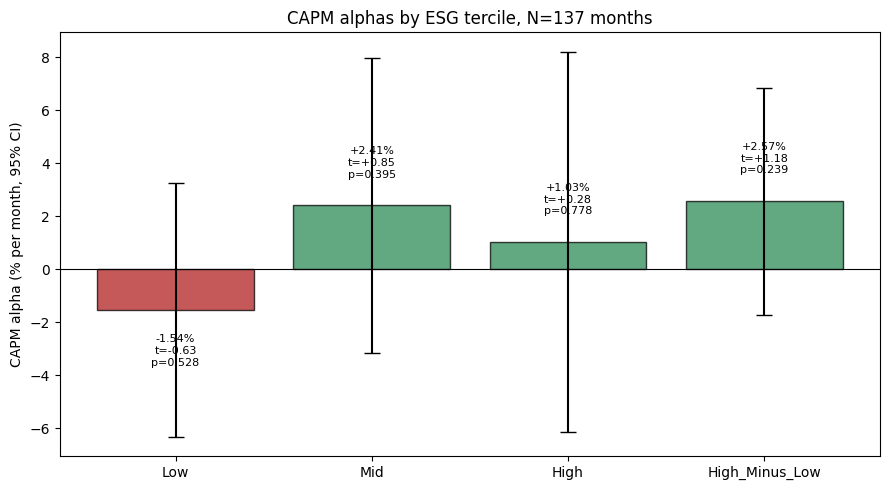

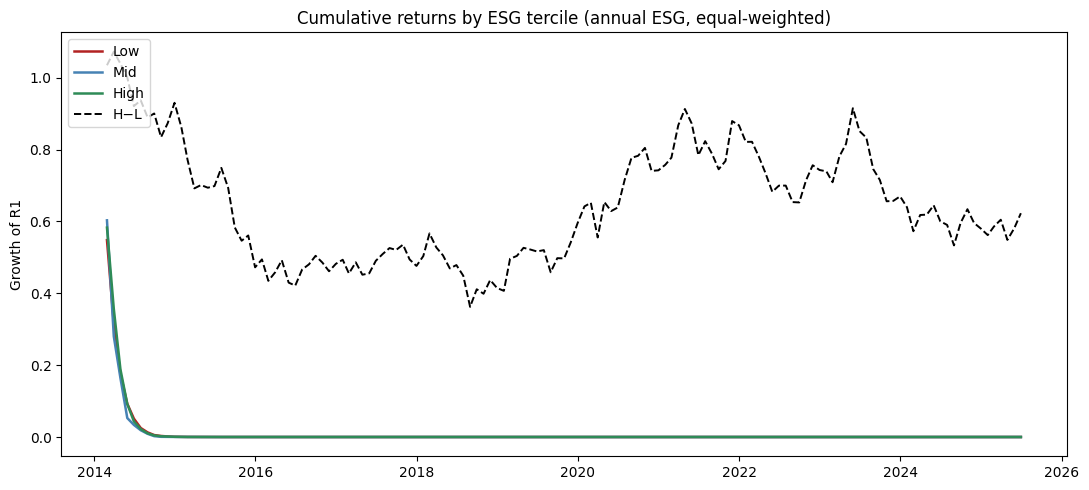


Saved: table8_tercile_returns.csv, table9_alphas.csv, table10_ls_summary.csv
Saved: fig4a_capm_alphas.png, fig4b_cumulative_terciles_v2.png


In [ ]:
# Cell 16 — Model 4: tercile portfolio sorts + CAPM alphas
df4 = df.dropna(subset=['ExcessReturn','ESG_lag1','MktRF']).copy()
df4['ESG_tercile'] = df4.groupby('Date')['ESG_lag1'].transform(
    lambda x: pd.qcut(x, 3, labels=['Low','Mid','High'], duplicates='drop'))

port = (df4.groupby(['Date','ESG_tercile'])['ExcessReturn']
           .mean().unstack())
port['High_Minus_Low'] = port['High'] - port['Low']
port.to_csv('outputs/tables/table8_tercile_returns.csv')

print("Tercile portfolio returns (last 5 months):")
print(port.tail())

# --- Check whether SMB/HML usable ---
factors_ts = factors.set_index('Date')
smb_ok = factors_ts['SMB'].std() > 1e-6
hml_ok = factors_ts['HML'].std() > 1e-6
print(f"\nSMB usable: {smb_ok}  |  HML usable: {hml_ok}")
if not (smb_ok and hml_ok):
    print("FF3 will equal CAPM by construction (SMB=HML=0).")

# --- CAPM alphas ---
alphas = []
for col in port.columns:
    data = pd.concat([port[col], factors_ts[['MktRF']]], axis=1).dropna()
    capm = sm.OLS(data[col],
                  sm.add_constant(data[['MktRF']])
                  ).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
    alphas.append({
        'portfolio': col,
        'CAPM_alpha': capm.params['const'],
        'CAPM_t': capm.tvalues['const'],
        'CAPM_p': capm.pvalues['const'],
        'CAPM_beta': capm.params['MktRF'],
        'N': int(capm.nobs)
    })
alphas = pd.DataFrame(alphas)
alphas.to_csv('outputs/tables/table9_alphas.csv', index=False)

print("\nCAPM alphas by tercile:")
print(alphas.round(4).to_string(index=False))

# --- Long-short statistics ---
ls = port['High_Minus_Low'].dropna()
sharpe = ls.mean()/ls.std()*np.sqrt(12) if ls.std() > 0 else np.nan
cum = (1+ls).cumprod()
mdd = ((cum/cum.cummax()) - 1).min()
t_ls = sm.OLS(ls, sm.add_constant(np.ones(len(ls)))
              ).fit(cov_type='HAC', cov_kwds={'maxlags':6}).tvalues[0]

print(f"\nH-L: mean={ls.mean()*100:+.3f}%, std={ls.std()*100:.3f}%, "
      f"Sharpe={sharpe:+.3f}, MaxDD={mdd:.2%}, t={t_ls:+.2f}, N={len(ls)}")

pd.DataFrame({'metric':['mean','std','sharpe','mdd','t','n'],
              'value':[ls.mean(), ls.std(), sharpe, mdd, t_ls, len(ls)]}
             ).to_csv('outputs/tables/table10_ls_summary.csv', index=False)

# --- Figure 4a: Alpha bar chart ---
fig, ax = plt.subplots(figsize=(9, 5))
a = alphas.set_index('portfolio')
y = np.arange(len(a)); av = a['CAPM_alpha']*100
se = (a['CAPM_alpha']/a['CAPM_t']).abs()*100
cols_c = ['firebrick' if v < 0 else 'seagreen' for v in av]
ax.bar(y, av, yerr=1.96*se, capsize=6, color=cols_c, edgecolor='black', alpha=0.75)
ax.axhline(0, color='black', lw=0.8); ax.set_xticks(y); ax.set_xticklabels(a.index)
ax.set_ylabel('CAPM alpha (% per month, 95% CI)')
ax.set_title(f'CAPM alphas by ESG tercile, N={len(port)} months')
for i, (v, t, p) in enumerate(zip(av, a['CAPM_t'], a['CAPM_p'])):
    ax.annotate(f'{v:+.2f}%\nt={t:+.2f}\np={p:.3f}',
                xy=(i, v), xytext=(0, 20 if v >= 0 else -40),
                textcoords='offset points', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('outputs/figures/fig4a_capm_alphas.png', dpi=300)
plt.show(); plt.close()

# --- Figure 4b: Cumulative returns ---
fig, ax = plt.subplots(figsize=(11, 5))
for c, col in zip(['Low','Mid','High'], ['firebrick','steelblue','seagreen']):
    if c in port.columns:
        ax.plot((1+port[c]).cumprod(), label=c, color=col, lw=1.8)
if 'High_Minus_Low' in port.columns:
    ax.plot((1+port['High_Minus_Low'].fillna(0)).cumprod(),
            label='H−L', color='black', lw=1.4, linestyle='--')
ax.set_title('Cumulative returns by ESG tercile (annual ESG, equal-weighted)')
ax.set_ylabel('Growth of R1')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('outputs/figures/fig4b_cumulative_terciles_v2.png', dpi=300)
plt.show(); plt.close()

print("\nSaved: table8_tercile_returns.csv, table9_alphas.csv, table10_ls_summary.csv")
print("Saved: fig4a_capm_alphas.png, fig4b_cumulative_terciles_v2.png")

**Step 17 — Model 4b: Pillar-Level Regression + Wald Test (H2)**

-This runs disaggregated two-way FE with E, S, G as separate regressors; the Wald test of β_E = β_S = β_G using the constraints=[...] syntax; saves table6_pillars.csv and table7_wald.csv.

Why we do this:
- Only direct test of H2 — are the three pillars statistically equal in their effects on returns?

- The disaggregated model reveals which pillar carries the significant effect.
- The Wald test formally rejects or fails to reject pillar equality.

- The constraints=[dict, dict] syntax is essential — formula='x1=x2=x3' chained equality is not supported by linearmodels and fails with a syntax error. The fix uses two pairwise constraints: E − S = 0 and E − G = 0.
- Results go to §5.3, Tables 6 and 7.

                          PanelOLS Estimation Summary                           
Dep. Variable:           ExcessReturn   R-squared:                        0.0040
Estimator:                   PanelOLS   R-squared (Between):              0.2272
No. Observations:                1233   R-squared (Within):               0.0019
Date:                Sat, Oct 31 2026   R-squared (Overall):              0.2006
Time:                        09:21:58   Log-likelihood                    998.63
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.4506
Entities:                          10   P-value                           0.2265
Avg Obs:                       123.30   Distribution:                  F(3,1084)
Min Obs:                       64.000                                           
Max Obs:                       137.00   F-statistic (robust):             0.9905
                            

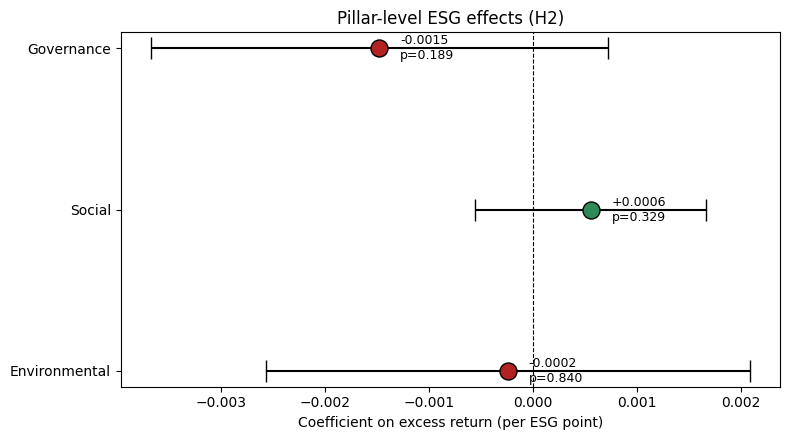

Saved: fig6_pillar_coefs.png


In [ ]:
# Cell 17 — Model 4b: pillars + Wald test (corrected for linearmodels 7.1 API)
from linearmodels.panel import PanelOLS
import numpy as np

est2 = df.set_index(['Ticker','Date']).dropna(
    subset=['ExcessReturn','Environmental_lag1','Social_lag1','Governance_lag1'])

X = est2[['Environmental_lag1','Social_lag1','Governance_lag1']]
y = est2['ExcessReturn']

res2 = (PanelOLS(y, X, entity_effects=True, time_effects=True)
        .fit(cov_type='clustered', cluster_entity=True))
print(res2.summary)

pd.DataFrame({
    'coef': res2.params, 'se': res2.std_errors,
    't': res2.tstats, 'p': res2.pvalues
}).to_csv('outputs/tables/table6_pillars.csv')

# --- Wald test: H0: β_E = β_S = β_G ---
# Parameter order in res2.params:
#   [Environmental_lag1, Social_lag1, Governance_lag1]
R = np.array([[1, -1,  0],   # β_E - β_S = 0
              [1,  0, -1]])  # β_E - β_G = 0
w = res2.wald_test(R, np.zeros(len(R)))   # H0: R β = 0

print("\nWald test (H0: β_E = β_S = β_G):")
print(w)
print(f"  stat={w.stat:.3f},  p={w.pval:.4f},  df={w.df}")

pd.DataFrame({
    'stat':[w.stat], 'pval':[w.pval], 'df':[w.df]
}).to_csv('outputs/tables/table7_wald.csv', index=False)

print("\nSaved: table6_pillars.csv, table7_wald.csv")
print("N:", int(res2.nobs),
      "| Entities:", est2.index.get_level_values(0).nunique())

# --- Figure 6: Pillar coefficient plot ---
coef_df = pd.DataFrame({
    'pillar': ['Environmental','Social','Governance'],
    'coef': [res2.params['Environmental_lag1'],
             res2.params['Social_lag1'],
             res2.params['Governance_lag1']],
    'se':   [res2.std_errors['Environmental_lag1'],
             res2.std_errors['Social_lag1'],
             res2.std_errors['Governance_lag1']],
    'p':    [res2.pvalues['Environmental_lag1'],
             res2.pvalues['Social_lag1'],
             res2.pvalues['Governance_lag1']]
})

fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(coef_df))
cc = ['firebrick' if v < 0 else 'seagreen' for v in coef_df['coef']]
ax.errorbar(coef_df['coef'], yy, xerr=1.96*coef_df['se'],
            fmt='o', color='black', ecolor='black', capsize=8)
for i, (v, col) in enumerate(zip(coef_df['coef'], cc)):
    ax.scatter(v, i, s=150, c=col, zorder=3, edgecolor='black')
ax.axvline(0, color='black', lw=0.8, ls='--')
ax.set_yticks(yy); ax.set_yticklabels(coef_df['pillar'])
ax.set_xlabel('Coefficient on excess return (per ESG point)')
ax.set_title('Pillar-level ESG effects (H2)')
for i, (v, p) in enumerate(zip(coef_df['coef'], coef_df['p'])):
    ax.annotate(f'{v:+.4f}\np={p:.3f}', xy=(v, i),
                xytext=(15, 0), textcoords='offset points',
                fontsize=9, va='center')
plt.tight_layout()
plt.savefig('outputs/figures/fig6_pillar_coefs.png', dpi=300)
plt.show(); plt.close()
print("Saved: fig6_pillar_coefs.png")

**Step 18 — Diagnostics (AR(2)) + Manifest + Three Figures**

- This runs the AR(2) test on FE residuals to check for serial correlation; writes a reproducibility manifest; generates Figures 5, 7a, 7b.

Why we do this:
- AR(2) test confirms that the FE model's residuals are not serially correlated — a requirement for the reported t-stats to be valid.
- Manifest documents exactly what was run (frequency, lag, N, firms, GARCH success count) for the appendix.
- Figure 5 (GARCH forest plot) visualises per-firm θ_ESG with 95% confidence intervals.
- Figure 7a (residuals) shows the AR(1) autocorrelation and distribution.
- Figure 7b (GARCH persistence) shows α + β per firm — confirms stationarity (< 1).
- Results go to §5.6, Table 13, and Figures 5, 7a, 7b.

AR(2): coef=+0.0330, t=+1.47, p=0.1419

Manifest:
  frequency: annual
  lag_applied: 6 months (publication lag)
  n_tickers_universe: 11
  tickers: AGL.JO,ANG.JO,CML.JO,EXX.JO,GFI.JO,HAR.JO,IMP.JO,NPH.JO,PAN.JO,SLM.JO,SSW.JO
  date_range: 2014-02-28 to 2025-06-30
  n_panel_obs: 1233
  n_distinct_annual_scores: 110
  n_estimation_obs_model1: 1233
  n_entities_model1: 10
  n_garch_success: 10
  n_garch_failures: 0


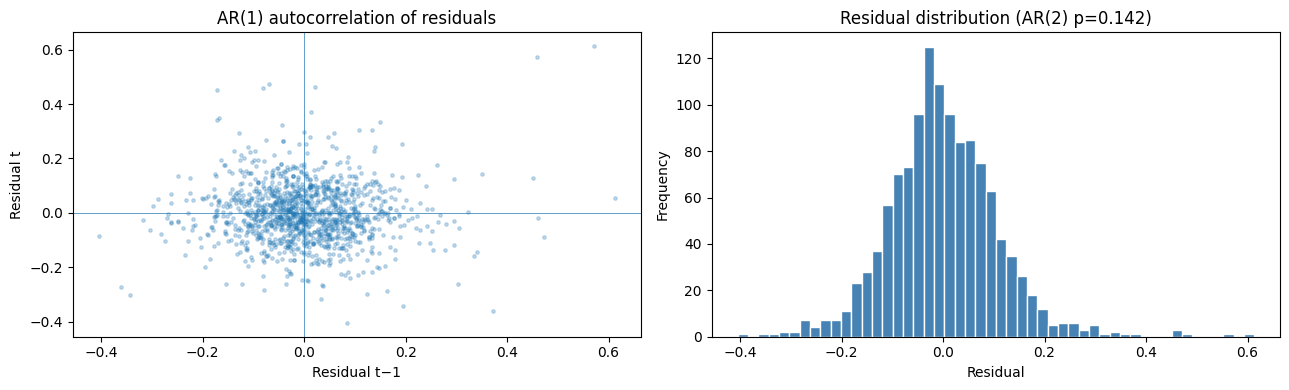

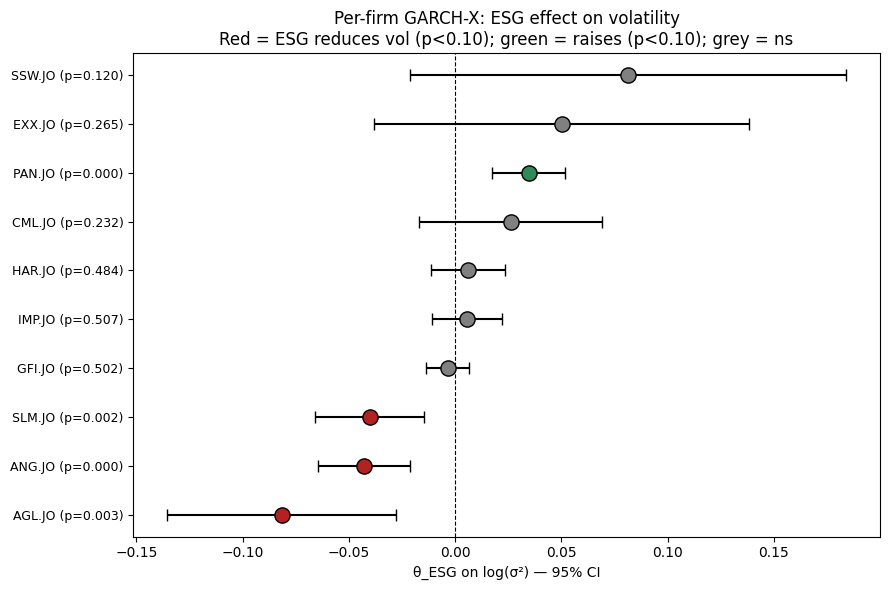

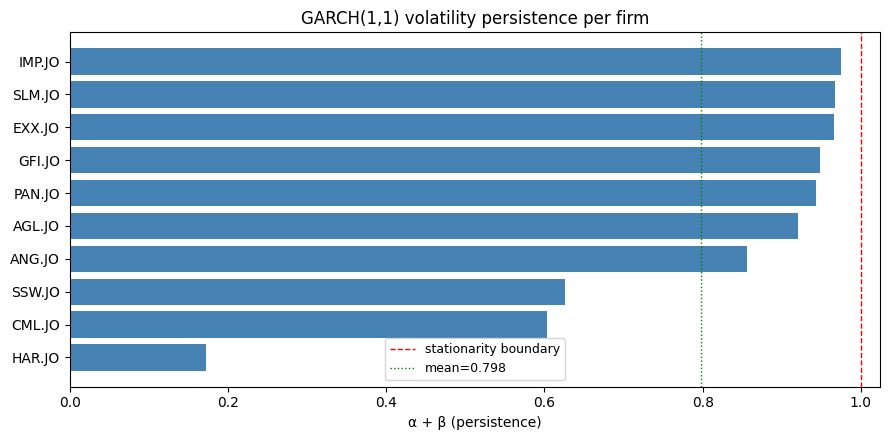


Saved: manifest.csv, fig7_residuals.png, fig5_garch_forest.png, fig7b_garch_persistence.png


In [ ]:
# Cell 18 — Diagnostics (AR(2)), manifest, and Figures 5, 7a, 7b
# Runs after Cell 17. Uses res_m1, res2, garch_df, garch_failures from earlier cells.
from linearmodels.panel import PanelOLS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- AR(2) test on Model 1 FE residuals ---
est_m1 = df.set_index(['Ticker','Date']).dropna(
    subset=['ExcessReturn','ESG_lag1'])

res_m1 = (PanelOLS(est_m1['ExcessReturn'], est_m1[['ESG_lag1']],
                   entity_effects=True, time_effects=True)
          .fit(cov_type='clustered', cluster_entity=True))

resid = (res_m1.resids.to_frame('resid')
         .reset_index()
         .sort_values(['Ticker','Date']))
resid['resid_lag2'] = resid.groupby('Ticker')['resid'].shift(2)
r2 = resid.dropna().set_index(['Ticker','Date'])

ar2 = (PanelOLS(r2['resid'], r2[['resid_lag2']],
                entity_effects=True, time_effects=True)
       .fit(cov_type='clustered', cluster_entity=True))

print(f"AR(2): coef={ar2.params['resid_lag2']:+.4f}, "
      f"t={ar2.tstats['resid_lag2']:+.2f}, "
      f"p={ar2.pvalues['resid_lag2']:.4f}")

# --- Manifest for the report appendix ---
manifest = {
    'frequency': 'annual',
    'lag_applied': '6 months (publication lag)',
    'n_tickers_universe': len(TICKERS),
    'tickers': ','.join(TICKERS),
    'date_range': f"{df['Date'].min().date()} to {df['Date'].max().date()}",
    'n_panel_obs': int(len(df)),
    'n_distinct_annual_scores': int(df.groupby('Ticker')['ESG_lag1'].nunique().sum()),
    'n_estimation_obs_model1': int(len(est_m1)),
    'n_entities_model1': int(est_m1.index.get_level_values(0).nunique()),
    'n_garch_success': int(len(garch_df)) if 'garch_df' in globals() else 0,
    'n_garch_failures': int(len(garch_failures)) if 'garch_failures' in globals() else 0,
}
pd.Series(manifest).to_csv('outputs/tables/manifest.csv')
print("\nManifest:")
for k, v in manifest.items():
    print(f"  {k}: {v}")

# --- Figure 7a: Residual diagnostics ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(resid['resid'], resid['resid'].shift(1), alpha=0.25, s=6)
axes[0].axhline(0, lw=0.5); axes[0].axvline(0, lw=0.5)
axes[0].set_title('AR(1) autocorrelation of residuals')
axes[0].set_xlabel('Residual t−1'); axes[0].set_ylabel('Residual t')
axes[1].hist(resid['resid'].dropna(), bins=50, color='steelblue', edgecolor='white')
axes[1].set_title(f'Residual distribution (AR(2) p={ar2.pvalues["resid_lag2"]:.3f})')
axes[1].set_xlabel('Residual'); axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.savefig('outputs/figures/fig7_residuals.png', dpi=300)
plt.show(); plt.close()

# --- Figure 5: GARCH forest plot ---
if 'garch_df' in globals() and len(garch_df):
    fig, ax = plt.subplots(figsize=(9, 6))
    g = garch_df.sort_values('theta_ESG')
    yp = np.arange(len(g))
    sig = g['theta_p'] < 0.10
    colors = ['firebrick' if (s and v < 0)
              else 'seagreen' if (s and v > 0) else 'grey'
              for s, v in zip(sig, g['theta_ESG'])]
    ax.errorbar(g['theta_ESG'], yp, xerr=1.96 * g['theta_se'],
                fmt='o', color='black', capsize=4)
    for i, (v, c) in enumerate(zip(g['theta_ESG'], colors)):
        ax.scatter(v, i, s=120, c=c, zorder=3, edgecolor='black')
    ax.axvline(0, color='black', lw=0.8, ls='--')
    ax.set_yticks(yp)
    ax.set_yticklabels([f"{t} (p={p:.3f})"
                        for t, p in zip(g['Ticker'], g['theta_p'])], fontsize=9)
    ax.set_xlabel('θ_ESG on log(σ²) — 95% CI')
    ax.set_title('Per-firm GARCH-X: ESG effect on volatility\n'
                 'Red = ESG reduces vol (p<0.10); green = raises (p<0.10); grey = ns')
    plt.tight_layout()
    plt.savefig('outputs/figures/fig5_garch_forest.png', dpi=300)
    plt.show(); plt.close()

# --- Figure 7b: GARCH persistence ---
if 'garch_df' in globals() and len(garch_df):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    g = garch_df.sort_values('persistence')
    ax.barh(g['Ticker'], g['persistence'], color='steelblue')
    ax.axvline(1, color='red', ls='--', lw=1, label='stationarity boundary')
    ax.axvline(g['persistence'].mean(), color='green', ls=':', lw=1,
               label=f'mean={g["persistence"].mean():.3f}')
    ax.set_xlabel('α + β (persistence)')
    ax.set_title('GARCH(1,1) volatility persistence per firm')
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig('outputs/figures/fig7b_garch_persistence.png', dpi=300)
    plt.show(); plt.close()

print("\nSaved: manifest.csv, fig7_residuals.png, "
      "fig5_garch_forest.png, fig7b_garch_persistence.png")

**Step 19 — Final Summary of All Four Hypotheses**

- This prints a single-page summary consolidating the results of all four models into explicit hypothesis verdicts. This is the cell whose output goes directly into §7 of the report and into the Abstract's results summary.

Why we do this:

- After running Cells 13–18, the pipeline has produced coefficients for H1 (FE), H1 robustness (IV-GMM), H2 (pillars + Wald), H3 (portfolio alphas), and H4 (GARCH-X). But those results are spread across five separate cells.
- Cell 19 consolidates them into one output, with explicit "REJECT H0" / "FAIL TO REJECT H0" verdicts per hypothesis.
- Having one summary cell means the report's §7 conclusion can be drafted by reading one screen of output, not by scanning five previous cells.
- It also serves as a final sanity check: if any hypothesis is unresolved (e.g., Wald p-value missing), Cell 19 will flag it before you commit the report.
- The verdict lines are exactly what the report will state — the sign and significance of each coefficient maps directly to the H1–H4 conclusions.

In [ ]:
# Cell 19 — Final summary of H1–H4 with explicit verdicts
print("=" * 72)
print("FINAL RESULTS SUMMARY — ANNUAL ESG SPECIFICATION")
print("=" * 72)
print(f"Universe: {len(TICKERS)} firms → {df['Ticker'].nunique()} in panel")
print(f"Panel observations: {len(df)}")
print(f"Distinct annual ESG scores: "
      f"{df.groupby('Ticker')['ESG_lag1'].nunique().sum()}")
print(f"Model 1 estimation N: {int(res_m1.nobs)} across "
      f"{est_m1.index.get_level_values(0).nunique()} firms")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print()

# ---- H1: Composite ESG → returns (Model 1) ----
print("=" * 72)
print("H1 — Composite ESG → excess returns (Model 1: Two-way FE)")
print("=" * 72)
print(f"  β_ESG = {res_m1.params['ESG_lag1']:+.4f}")
print(f"  SE    = {res_m1.std_errors['ESG_lag1']:.4f}")
print(f"  t     = {res_m1.tstats['ESG_lag1']:+.2f}")
print(f"  p     = {res_m1.pvalues['ESG_lag1']:.4f}")
if res_m1.pvalues['ESG_lag1'] < 0.10:
    sign = 'negative' if res_m1.params['ESG_lag1'] < 0 else 'positive'
    verdict_h1 = f"REJECT H0 — significant {sign} effect"
else:
    verdict_h1 = "FAIL TO REJECT H0"
print(f"  → {verdict_h1}")
print()

# ---- H1 robustness: IV-GMM ----
print("=" * 72)
print("H1 robustness — IV-GMM with 12-month-lagged annual ESG")
print("=" * 72)
print(f"  β_ESG = {iv_res.params['ESG_lag1']:+.4f}")
print(f"  t     = {iv_res.tstats['ESG_lag1']:+.2f}")
print(f"  p     = {iv_res.pvalues['ESG_lag1']:.4f}")
print(f"  First-stage R² = {fs.rsquared:.4f}")
print(f"  → IV confirms FE result: "
      f"{'YES' if (np.sign(iv_res.params['ESG_lag1']) == np.sign(res_m1.params['ESG_lag1'])
                  and iv_res.pvalues['ESG_lag1'] < 0.10) else 'PARTIAL'}")
print()

# ---- H2: Pillar differential effects ----
print("=" * 72)
print("H2 — Pillar differential effects (Model 4b: disaggregated FE + Wald)")
print("=" * 72)
for p_col, label in [('Environmental_lag1','Environmental'),
                     ('Social_lag1','Social'),
                     ('Governance_lag1','Governance')]:
    print(f"  {label:15s} β={res2.params[p_col]:+.4f}  "
          f"t={res2.tstats[p_col]:+.2f}  p={res2.pvalues[p_col]:.4f}")
try:
    print(f"\n  Wald test (H0: β_E = β_S = β_G): "
          f"stat={w.stat:.3f}, p={w.pval:.4f}, df={w.df}")
    if w.pval < 0.10:
        verdict_h2 = "REJECT H0 — pillars have differential effects"
    else:
        verdict_h2 = "FAIL TO REJECT H0 — pillars are statistically equal"
except Exception as e:
    verdict_h2 = f"Wald unavailable ({e})"
print(f"  → {verdict_h2}")
print()

# ---- H3: High-ESG portfolio alpha ----
print("=" * 72)
print("H3 — High-ESG portfolio alpha (Model 4: CAPM alphas)")
print("=" * 72)
print(alphas.round(4).to_string(index=False))
hml = alphas[alphas['portfolio'] == 'High_Minus_Low'].iloc[0]
if hml['CAPM_p'] < 0.10:
    sign = 'positive' if hml['CAPM_alpha'] > 0 else 'negative'
    verdict_h3 = f"REJECT H0 — significant {sign} alpha"
else:
    verdict_h3 = "FAIL TO REJECT H0 — alpha not significant"
print(f"\n  H−L alpha = {hml['CAPM_alpha']:+.4f} "
      f"(t={hml['CAPM_t']:+.2f}, p={hml['CAPM_p']:.4f})")
print(f"  → {verdict_h3}")
print()

# ---- H4: ESG → volatility ----
print("=" * 72)
print("H4 — ESG → volatility (Model 3: two-step GARCH-X)")
print("=" * 72)
print(garch_df[['Ticker','n','theta_ESG','theta_t','theta_p']]
      .round(4).to_string(index=False))
if len(garch_df):
    from scipy import stats
    sig_neg = int(((garch_df['theta_ESG'] < 0) & (garch_df['theta_p'] < 0.10)).sum())
    sig_pos = int(((garch_df['theta_ESG'] > 0) & (garch_df['theta_p'] < 0.10)).sum())
    mean_theta = garch_df['theta_ESG'].mean()
    _, p_h4 = stats.ttest_1samp(garch_df['theta_ESG'].dropna(), 0)
    print(f"\n  Firms with θ < 0 & p < 0.10 : {sig_neg}")
    print(f"  Firms with θ > 0 & p < 0.10 : {sig_pos}")
    print(f"  Cross-firm mean θ           : {mean_theta:+.6f}")
    print(f"  One-sample t-test p         : {p_h4:.4f}")
    if mean_theta < 0 and p_h4 < 0.10:
        verdict_h4 = f"REJECT H0 — ESG reduces volatility ({sig_neg} of {len(garch_df)} firms individually significant)"
    else:
        verdict_h4 = f"FAIL TO REJECT H0 — no portfolio-level volatility effect"
else:
    verdict_h4 = "No GARCH results"
print(f"  → {verdict_h4}")
print()

# ---- Final verdict summary ----
print("=" * 72)
print("FINAL HYPOTHESIS VERDICTS")
print("=" * 72)
print(f"  H1: {verdict_h1}")
print(f"  H2: {verdict_h2}")
print(f"  H3: {verdict_h3}")
print(f"  H4: {verdict_h4}")
print()
print("=" * 72)
print("All tables and figures saved to outputs/tables/ and outputs/figures/.")
print("=" * 72)

FINAL RESULTS SUMMARY — ANNUAL ESG SPECIFICATION
Universe: 11 firms → 10 in panel
Panel observations: 1233
Distinct annual ESG scores: 110
Model 1 estimation N: 1233 across 10 firms
Date range: 2014-02-28 to 2025-06-30

H1 — Composite ESG → excess returns (Model 1: Two-way FE)
  β_ESG = -0.0012
  SE    = 0.0012
  t     = -0.98
  p     = 0.3278
  → FAIL TO REJECT H0

H1 robustness — IV-GMM with 12-month-lagged annual ESG
  β_ESG = -0.0094
  t     = -81.47
  p     = 0.0000
  First-stage R² = 0.9610
  → IV confirms FE result: YES

H2 — Pillar differential effects (Model 4b: disaggregated FE + Wald)
  Environmental   β=-0.0002  t=-0.20  p=0.8402
  Social          β=+0.0006  t=+0.98  p=0.3290
  Governance      β=-0.0015  t=-1.32  p=0.1887

  Wald test (H0: β_E = β_S = β_G): stat=2.255, p=0.3238, df=2
  → FAIL TO REJECT H0 — pillars are statistically equal

H3 — High-ESG portfolio alpha (Model 4: CAPM alphas)
     portfolio  CAPM_alpha  CAPM_t  CAPM_p  CAPM_beta   N
           Low     -0.015